# 01 · Source overview: what is in each file, and do the files fit together?

**Stage 2, checklist questions 1-3 and 7.** Before any cleaning we need to know what each of the four source files
contains, whether the "legacy" and "current" halves of each pair share a layout, where their date ranges meet, and
what one row represents.

| Label | File | Expected coverage |
|---|---|---|
| contracts_legacy | `2009-2023-contractHistoryHistorical-...csv` | Jan 2009 - May 2023 |
| contracts_current | `contractHistoryComplete-...csv` | Jun 2023 onwards |
| tenders_legacy | `2009-2022-tenderNoticeHistorical-...csv` | 2009 - Aug 2022 |
| tenders_current | `tenderNoticeComplete-...csv` | Aug 2022 onwards |

All data is loaded through `spendpipe.sources`, which trims whitespace, treats `N/A` / `NULL` as missing and never
reads contact or address columns. The full column-by-column profile is in `data/processed/profile/*.txt`
(from `scripts/profile_sources.py`); this notebook covers the questions that need the files side by side.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from spendpipe import sources as S, eda
eda.apply_style()
pd.set_option("display.max_columns", 30, "display.width", 160, "display.max_colwidth", 60)

In [2]:
data = {label: S.load(label) for label in S.SOURCES}
pd.DataFrame({label: {"rows": len(df), "file": S.find_file(label).name} for label, df in data.items()}).T

,rows,file
contracts_current,23238,contractHistoryComplete-contratsOctroyesComplet(1).csv
contracts_legacy,486151,2009-2023-contractHistoryHistorical-contratsOctroyesHist...
tenders_current,30830,tenderNoticeComplete-avisAppelOffresComplet.csv
tenders_legacy,71310,2009-2022-tenderNoticeHistorical-AvisAppelOffresHistoriq...


## 1. Do the legacy and current files share a layout?

The comparison uses the **full header** of each file (not just the columns we load), so a renamed or missing column
anywhere would show up here.

In [3]:
headers = {label: pd.read_csv(S.find_file(label), nrows=0, encoding="utf-8-sig").columns.tolist() for label in S.SOURCES}
for a, b in [("contracts_legacy", "contracts_current"), ("tenders_legacy", "tenders_current")]:
    same_names, same_order = set(headers[a]) == set(headers[b]), headers[a] == headers[b]
    print(f"{a} vs {b}: {len(headers[a])} vs {len(headers[b])} columns | same names: {same_names} | same order: {same_order}")
shared = set(headers["contracts_current"]) & set(headers["tenders_current"])
print(f"contract and tender files share {len(shared)} column names")

contracts_legacy vs contracts_current: 91 vs 91 columns | same names: True | same order: True
tenders_legacy vs tenders_current: 67 vs 67 columns | same names: True | same order: True
contract and tender files share 56 column names


Same layout in each pair. But a shared layout does not mean the same content: notebook 02 shows that fill rates
differ sharply *within* the contract files, depending on which record system wrote the row.

## 2. Where do the date ranges meet?

Contracts are placed in time by **award date**, tenders by **publication date**. For each file: the range, and the
rows just either side of the boundary.

In [4]:
typed = {label: S.parse_types(df) for label, df in data.items()}
date_of = {"contracts_legacy": "award_date", "contracts_current": "award_date",
           "tenders_legacy": "publication_date", "tenders_current": "publication_date"}
rows = []
for label, col in date_of.items():
    d = typed[label][col]
    rows.append({"file": label, "date used": col, "first": d.min().date(), "last": d.max().date(),
                 "rows with no date": int(d.isna().sum())})
pd.DataFrame(rows).set_index("file")

,date used,first,last,rows with no date
file,,,,
contracts_legacy,award_date,2009-01-01,2023-05-31,69040
contracts_current,award_date,2023-06-01,2026-09-25,305
tenders_legacy,publication_date,2010-03-16,2022-08-05,0
tenders_current,publication_date,2022-08-08,2026-10-22,0


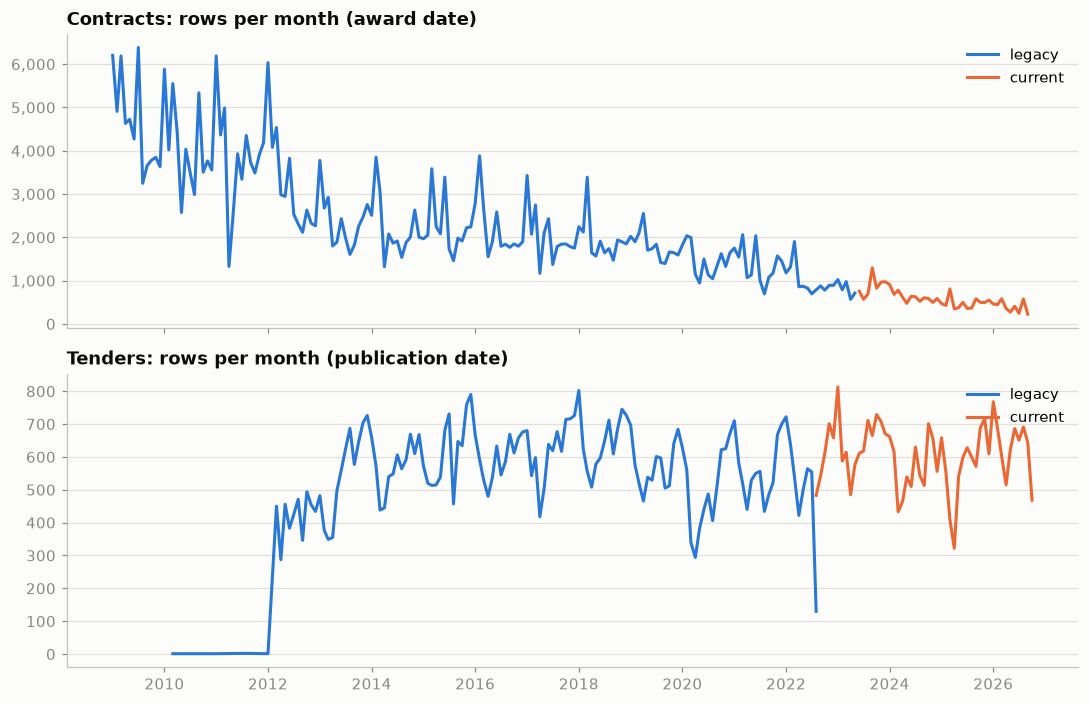

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)
for ax, kind in zip(axes, ["contracts", "tenders"]):
    for label in [f"{kind}_legacy", f"{kind}_current"]:
        d = typed[label][date_of[label]].dropna()
        monthly = d.dt.to_period("M").value_counts().sort_index()
        monthly.index = monthly.index.to_timestamp()
        ax.plot(monthly.index, monthly.values, color=eda.SOURCE_COLORS[label], label=label.split("_")[1])
    ax.set_title(f"{kind.capitalize()}: rows per month ({'award' if kind == 'contracts' else 'publication'} date)")
    ax.yaxis.set_major_formatter(eda.thousands())
    ax.legend(loc="upper right")
fig.tight_layout()

The halves meet without a gap or an overlap in their main dates. Two things to carry forward:

* Contract rows per month fall steadily, from 4,000-6,000 in 2009 to under 1,000 by 2022, and the current file
  continues at about that level. Whether that is a real change in buying or a change in what gets recorded is a
  stage 3 question (notebook 02 has first evidence).
* The legacy tender file has almost nothing before 2012, and its last month (Aug 2022) is partial. Tender trends
  should start in 2012.

Meeting cleanly on dates is not the same as meeting cleanly on *contracts*: does any contract number appear in both
contract files, or any notice in both tender files?

In [6]:
def overlap(a, b, key):
    return set(data[a][key].dropna()) & set(data[b][key].dropna())

shared_contracts = overlap("contracts_legacy", "contracts_current", "contract_number")
pairs = lambda df: set(zip(df.contract_number, df.amendment_number))
print(f"contract numbers in both contract files: {len(shared_contracts):,}")
print(f"identical (contract, amendment) rows in both: {len(pairs(data['contracts_legacy']) & pairs(data['contracts_current'])):,}")
print(f"tender reference numbers in both tender files: {len(overlap('tenders_legacy', 'tenders_current', 'reference_number')):,}")
print(f"tender solicitation numbers in both tender files: {len(overlap('tenders_legacy', 'tenders_current', 'solicitation_number')):,}")

contract numbers in both contract files: 405


identical (contract, amendment) rows in both: 0
tender reference numbers in both tender files: 0
tender solicitation numbers in both tender files: 224


In [7]:
example = sorted(shared_contracts)[0]
cols = ["source", "contract_number", "amendment_number", "award_date", "amendment_date", "total_value"]
pd.concat([data["contracts_legacy"], data["contracts_current"]]).query("contract_number == @example")[cols] \
  .sort_values("amendment_number")

,source,contract_number,amendment_number,award_date,amendment_date,total_value
19699,contracts_legacy,08843-170424/001/ZQ,000,2018-06-03,NaN,15179413.12
403183,contracts_legacy,08843-170424/001/ZQ,001,2018-06-03,2018-11-21,15179413.12
405482,contracts_legacy,08843-170424/001/ZQ,002,2018-06-03,2019-01-15,15179413.12
409634,contracts_legacy,08843-170424/001/ZQ,003,2018-06-03,2019-03-26,15179413.12
412985,contracts_legacy,08843-170424/001/ZQ,004,2018-06-03,2019-06-03,15179413.12
417919,contracts_legacy,08843-170424/001/ZQ,005,2018-06-03,2019-09-24,15179413.12
423626,contracts_legacy,08843-170424/001/ZQ,006,2018-06-03,2020-02-17,15179413.12
437559,contracts_legacy,08843-170424/001/ZQ,007,2018-06-03,2021-01-04,15179413.12
447515,contracts_legacy,08843-170424/001/ZQ,008,2018-06-03,2021-07-15,15179413.12
453739,contracts_legacy,08843-170424/001/ZQ,009,2018-06-03,2022-01-06,15179413.12


No row is duplicated, but the contract is split. In this example amendments 012-018 (dated 2023-2026) stayed in
the legacy file while amendment 019 moved to the current file, and it carries a different award date. So the split
is not by amendment date. The next cell tests a different rule: **each row is filed by its own award date, or by its
amendment date when the award date is blank.**

In [8]:
window = {"contracts_legacy": (None, "2023-05-31"), "contracts_current": ("2023-06-01", None)}
for label, (lo, hi) in window.items():
    df = data[label]
    filing_date = df.award_date.fillna(df.amendment_date)
    outside = (filing_date > hi) if hi else (filing_date < lo)
    print(f"{label}: rows {len(df):,} | no award date {df.award_date.isna().sum():,} | no award AND no amendment date "
          f"{(df.award_date.isna() & df.amendment_date.isna()).sum():,} | rows outside the window by that rule {outside.sum():,}")

both = pd.concat([data["contracts_legacy"], data["contracts_current"]])
split = both[both.contract_number.isin(shared_contracts)]
n_dates = split.groupby("contract_number").award_date.nunique()
print(f"split contracts with no award date on any row: {(n_dates == 0).sum()} | with rows carrying "
      f"two or more different award dates: {(n_dates > 1).sum()} | other: {(n_dates == 1).sum()}")

contracts_legacy: rows 486,151 | no award date 69,040 | no award AND no amendment date 0 | rows outside the window by that rule 0
contracts_current: rows 23,238 | no award date 305 | no award AND no amendment date 0 | rows outside the window by that rule 0
split contracts with no award date on any row: 236 | with rows carrying two or more different award dates: 159 | other: 10


The rule holds for every row. A contract splits when its rows disagree on that date, either because no row has an
award date (so each amendment is filed by its own date) or because rows carry different award dates. Anything that
reads the current file alone counts these contracts as new. The fix (stack both files, then decide one award date
per contract) is a stage 3 decision.

## 3. What does one row represent?

For contracts: one record per (contract number, amendment number). Checked on the trimmed values. And because
trimming matters, the raw contract-number column is also read **untrimmed** to measure how many duplicates
whitespace would create.

In [9]:
for label in ["contracts_legacy", "contracts_current"]:
    df = data[label]
    raw = pd.read_csv(S.find_file(label), usecols=[S.CONTRACT_COLUMNS["contract_number"]], dtype=str,
                      keep_default_na=False, encoding="utf-8-sig").iloc[:, 0]
    print(f"{label}: {len(df):,} rows | repeated (contract, amendment) pairs: "
          f"{df.duplicated(['contract_number', 'amendment_number']).sum():,} | contracts {df.contract_number.nunique():,} | "
          f"distinct numbers before trimming {raw.nunique():,} | cells with edge whitespace {(raw != raw.str.strip()).sum():,}")
for label in ["tenders_legacy", "tenders_current"]:
    df = data[label]
    print(f"{label}: {len(df):,} rows | distinct reference numbers {df.reference_number.nunique():,} | "
          f"distinct solicitation numbers {df.solicitation_number.nunique():,}")

contracts_legacy: 486,151 rows | repeated (contract, amendment) pairs: 0 | contracts 210,543 | distinct numbers before trimming 210,608 | cells with edge whitespace 81


contracts_current: 23,238 rows | repeated (contract, amendment) pairs: 0 | contracts 14,169 | distinct numbers before trimming 14,193 | cells with edge whitespace 67
tenders_legacy: 71,310 rows | distinct reference numbers 71,310 | distinct solicitation numbers 70,083
tenders_current: 30,830 rows | distinct reference numbers 30,830 | distinct solicitation numbers 28,062


For tenders, `referenceNumber` is different on **every** row, so it identifies a notice (or notice version), not a
procurement. Several rows can share a solicitation number. Notebook 04 looks at what that means for linking.

## 4. Placeholder dates

In [10]:
for label in ["contracts_legacy", "contracts_current"]:
    end = typed[label]["end_date"]
    print(f"{label}: end dates in or after 2060: {(end.dt.year >= 2060).sum():,} | before 1990: {(end.dt.year < 1990).sum():,} | "
          f"top far-future years: {end[end.dt.year >= 2060].dt.year.value_counts().head(4).to_dict()}")
for label in ["tenders_legacy", "tenders_current"]:
    close = typed[label]["closing_date"]
    print(f"{label}: closing dates in or after 2060: {(close.dt.year >= 2060).sum():,}")

contracts_legacy: end dates in or after 2060: 8,465 | before 1990: 28 | top far-future years: {2100: 8221, 2099: 29, 9999: 25, 3000: 13}
contracts_current: end dates in or after 2060: 83 | before 1990: 0 | top far-future years: {2099: 48, 2100: 23, 2126: 11, 3000: 1}
tenders_legacy: closing dates in or after 2060: 4
tenders_current: closing dates in or after 2060: 13


## Findings

1. **Layout:** each legacy/current pair has identical columns in identical order (91 for contracts, 67 for tenders).
2. **Boundaries:** contract award dates meet cleanly (legacy ends 2023-05-31, current starts 2023-06-01). Tender
   publication dates also meet (2022-08-05 / 2022-08-08). The publisher files each contract row by its award date,
   or by its amendment date when that is blank, with no exceptions.
3. **Split contracts:** 405 contract numbers appear in both contract files, with no duplicated row. 236 have no
   award date anywhere, 159 have rows that disagree on award date, and 10 have an award date only on their legacy
   rows. The pipeline must stack both files before collapsing to contracts.
4. **Grain:** one row per (contract number, amendment number), no repeats. Trimming merges 65 legacy and 24 current
   contract numbers that differ only by whitespace.
5. **Tender grain:** `referenceNumber` is unique on every row (a notice ID), so it cannot link to contracts.
6. **Placeholders:** 8,465 legacy and 83 current end dates are in 2060 or later (mostly 2100), and 28 legacy end
   dates are before 1990. v1 treated these as unknown; the rule for this pipeline is a stage 4 decision.

Logged in `docs/project_log.md` (entries 1, 2, 4).